# Projet : pricing d'options par Monte-Carlo
### Du modèle de Black-Scholes-Merton à la simulation : un pricer configurable pour options européennes, exotiques et américaines

**Réalisé par Kim TRINH**

Dans ce projet, je construis un pricer d'options par simulation de Monte-Carlo. C'est le troisième paradigme de valorisation, complémentaire des deux autres que j'ai déjà explorés : la formule fermée de Black-Scholes (analytique) et le réseau de neurones du projet APR (apprentissage automatique). Le Monte-Carlo est l'outil de référence du quant dès que le payoff devient complexe : options path-dependent, options sur plusieurs sous-jacents, ou modèles sans solution analytique.

L'idée est simple et puissante : le prix d'une option est l'espérance actualisée de son payoff sous la probabilité risque-neutre, et une espérance s'estime en simulant un grand nombre de scénarios puis en faisant la moyenne. Je conçois ce notebook comme un **outil réutilisable** : un bloc de configuration placé juste après les imports me permet de pricer n'importe quel sous-jacent et n'importe quel type de produit en ne modifiant que quelques variables. Je pars de l'exemple le plus classique (une option à la monnaie), je valide systématiquement mes résultats contre la formule de Black-Scholes, puis j'enrichis progressivement : réduction de variance, calcul des Greeks, options exotiques, options américaines, et enfin une fonction `pricer` unique qui rassemble le tout.

# Plan du notebook

**A. Configuration et fondations**
1. Partie I : imports, configuration et paramètres globaux
2. Partie II : le modèle de Black-Scholes-Merton (référence analytique)
3. Partie III : simulation du sous-jacent (mouvement brownien géométrique)

**B. Pricing d'une option européenne**
4. Partie IV : pricing Monte-Carlo et convergence
5. Partie V : réduction de variance (antithétique, variable de contrôle)

**C. Sensibilités et payoffs complexes**
6. Partie VI : les Greeks par Monte-Carlo
7. Partie VII : options path-dependent (asiatique, barrière)
8. Partie VIII : options américaines (Longstaff-Schwartz)

**D. Validation, outil unifié et bilan**
9. Partie IX : un pricer unifié et réutilisable
10. Partie X : validation sur tout le spectre de moneyness (ITM, ATM, OTM)
11. Partie XI : bilan et limites

# Partie I : imports, configuration et paramètres globaux

Je commence par les imports, puis je centralise dans un **bloc de configuration** toutes les variables qui changent d'un cas à l'autre. C'est ce bloc qui rend le pricer réellement réutilisable : pour valoriser un autre sous-jacent ou un autre produit, je ne modifie que ces quelques lignes, et tout le reste du notebook s'y adapte automatiquement. Je sépare trois familles de réglages : les paramètres de marché du sous-jacent, la définition du produit à pricer, et les réglages de simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.rcParams["figure.figsize"] = (10, 4)

# Configuration : pour pricer un autre sous-jacent ou un autre produit,
# je ne touche qu'a ce bloc, le reste du notebook s'y adapte.

# Le sous-jacent (parametres de marche)
NOM_SOUS_JACENT = "Action ABC"  # sert uniquement a l'affichage
prix_initial = 100.0  # S0, prix spot aujourd'hui
taux = 0.05  # r, taux sans risque annuel (compose en continu)
volatilite = 0.20  # sigma, volatilite annuelle
maturite = 1.0  # T, maturite en annees

# Le produit a pricer
TYPE_OPTION = "call"  # "call" ou "put"
prix_exercice = 100.0  # K, strike. K<S0 -> call ITM / put OTM ; K=S0 -> ATM ; K>S0 -> call OTM / put ITM
BARRIERE = 130.0  # niveau de barriere, pour une option a barriere

# Reglages de simulation
NB_SIMULATIONS = 200_000  # nb de trajectoires Monte-Carlo
NB_PAS = 252  # nb de pas de temps (produits path-dependent)
GRAINE = 42  # graine aleatoire, pour la reproductibilite

np.random.seed(GRAINE)
print(f"Sous-jacent : {NOM_SOUS_JACENT}  |  S0 = {prix_initial} | r = {taux:.2%} | sigma = {volatilite:.2%} | T = {maturite} an")
print(f"Produit     : {TYPE_OPTION} de strike K = {prix_exercice}  (barriere eventuelle B = {BARRIERE})")
print(f"Simulation  : {NB_SIMULATIONS:,} trajectoires | {NB_PAS} pas | graine {GRAINE}")

Sous-jacent : Action ABC  |  S0 = 100.0 | r = 5.00% | sigma = 20.00% | T = 1.0 an
Produit     : call de strike K = 100.0  (barriere eventuelle B = 130.0)
Simulation  : 200,000 trajectoires | 252 pas | graine 42


# Partie II : le modèle de Black-Scholes-Merton (référence analytique)

Avant de simuler quoi que ce soit, je pose la référence. Le modèle de Black-Scholes-Merton suppose que le sous-jacent suit un mouvement brownien géométrique et donne une formule fermée pour le prix d'un call ou d'un put européen :
$$C = S_0\,N(d_1) - K e^{-rT} N(d_2), \qquad d_1 = \frac{\ln(S_0/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}, \quad d_2 = d_1 - \sigma\sqrt{T}$$

Cette formule est ma vérité terrain : tout mon pricer Monte-Carlo devra la retrouver sur les options européennes. C'est ce qui me permettra de valider le code avant de l'appliquer à des cas où, justement, aucune formule n'existe. Je calcule le prix du produit configuré.

In [2]:
def prix_black_scholes(S, K, r, sigma, T, type_option="call"):
    d1 = (np.log(S/K) + (r + sigma**2/2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    if type_option == "call":
        return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    return K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)

prix_vanille_bs = prix_black_scholes(prix_initial, prix_exercice, taux, volatilite, maturite, TYPE_OPTION)
call_bs = prix_black_scholes(prix_initial, prix_exercice, taux, volatilite, maturite, "call")
put_bs  = prix_black_scholes(prix_initial, prix_exercice, taux, volatilite, maturite, "put")
print(f"Prix Black-Scholes du {TYPE_OPTION} configure : {prix_vanille_bs:.4f}")
print(f"(rappel  ->  call : {call_bs:.4f}   |   put : {put_bs:.4f})")

Prix Black-Scholes du call configure : 10.4506
(rappel  ->  call : 10.4506   |   put : 5.5735)


La formule de Black-Scholes donne 10.45 pour le call et 5.57 pour le put configures. Ces deux valeurs servent de reference analytique : tout le reste du notebook s'y compare pour valider les methodes de simulation.

# Partie III : simulation du sous-jacent (mouvement brownien géométrique)

Le cœur du Monte-Carlo est la simulation des trajectoires du sous-jacent. Sous la probabilité risque-neutre, le rendement espéré du sous-jacent n'est pas son rendement réel mais le taux sans risque $r$ : c'est le point conceptuel central du pricing par arbitrage. La solution exacte du mouvement brownien géométrique me donne directement le prix à maturité :
$$S_T = S_0 \exp\left((r - \tfrac{\sigma^2}{2})T + \sigma\sqrt{T}\,Z\right), \qquad Z \sim \mathcal{N}(0,1)$$

Pour une option européenne, seul $S_T$ compte, donc je tire directement le prix final. Pour les options qui dépendent de tout le chemin (Partie VII), je simule la trajectoire complète pas à pas. Je trace quelques trajectoires et la distribution de $S_T$, qui est lognormale.

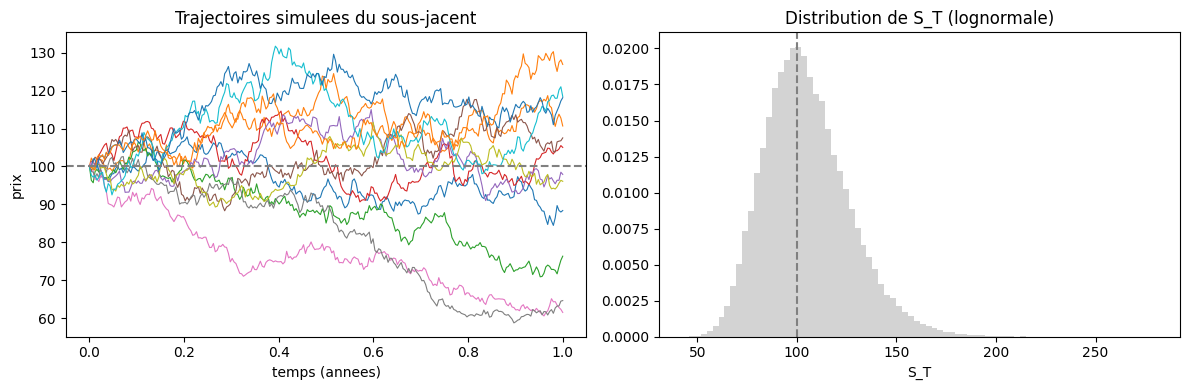

In [3]:
def simuler_prix_final(S, r, sigma, T, n, graine=0):
    rng = np.random.default_rng(graine)
    Z = rng.standard_normal(n)
    return S * np.exp((r - sigma**2/2)*T + sigma*np.sqrt(T)*Z)

def simuler_trajectoires(S, r, sigma, T, n, nb_pas, graine=0):
    rng = np.random.default_rng(graine)
    dt = T / nb_pas
    Z = rng.standard_normal((n, nb_pas))
    increments = (r - sigma**2/2)*dt + sigma*np.sqrt(dt)*Z
    chemins = S * np.exp(np.cumsum(increments, axis=1))
    return np.concatenate([np.full((n, 1), S), chemins], axis=1)  # je prefixe S0

trajectoires = simuler_trajectoires(prix_initial, taux, volatilite, maturite, 12, NB_PAS, graine=GRAINE)
prix_finaux = simuler_prix_final(prix_initial, taux, volatilite, maturite, 100_000, graine=GRAINE)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(np.linspace(0, maturite, trajectoires.shape[1]), trajectoires.T, lw=0.8)
a1.axhline(prix_exercice, ls="--", color="grey"); a1.set_title("Trajectoires simulees du sous-jacent")
a1.set_xlabel("temps (annees)"); a1.set_ylabel("prix")
a2.hist(prix_finaux, bins=80, density=True, color="lightgrey", edgecolor="none")
a2.axvline(prix_exercice, ls="--", color="grey"); a2.set_title("Distribution de S_T (lognormale)")
a2.set_xlabel("S_T")
plt.tight_layout(); plt.show()

L'histogramme des prix finaux simules suit une loi log-normale (le sous-jacent ne peut pas devenir negatif), centree autour de S0 x exp(rT). C'est la brique de base : a partir de ces trajectoires risque-neutres, on price n'importe quel payoff par moyenne actualisee.

# Partie IV : pricing Monte-Carlo d'une option européenne et convergence

Le principe tient en une ligne : le prix est l'espérance actualisée du payoff, que j'estime par la moyenne empirique sur un grand nombre de simulations.
$$\text{prix} = e^{-rT}\,\mathbb{E}[\text{payoff}(S_T)] \approx e^{-rT}\,\frac{1}{n}\sum_{i=1}^n \text{payoff}(S_T^{(i)})$$

Comme c'est une estimation statistique, je l'accompagne toujours de son **erreur standard** $\sigma_{\text{payoff}}/\sqrt{n}$ et d'un intervalle de confiance à 95 pour cent. Le point clé à retenir sur le Monte-Carlo est sa vitesse de convergence : l'erreur décroît en $1/\sqrt{n}$, indépendamment de la dimension. C'est lent (diviser l'erreur par 10 demande 100 fois plus de simulations) mais robuste, et c'est ce qui rend le Monte-Carlo imbattable en grande dimension là où les méthodes de grille explosent. Je vérifie sur deux graphiques que mon prix converge vers Black-Scholes et que l'erreur suit bien la pente $-1/2$ en échelle logarithmique.

Prix Monte-Carlo (call) : 10.4634  +/- 0.0649  (IC 95%)
Prix Black-Scholes      : 10.4506


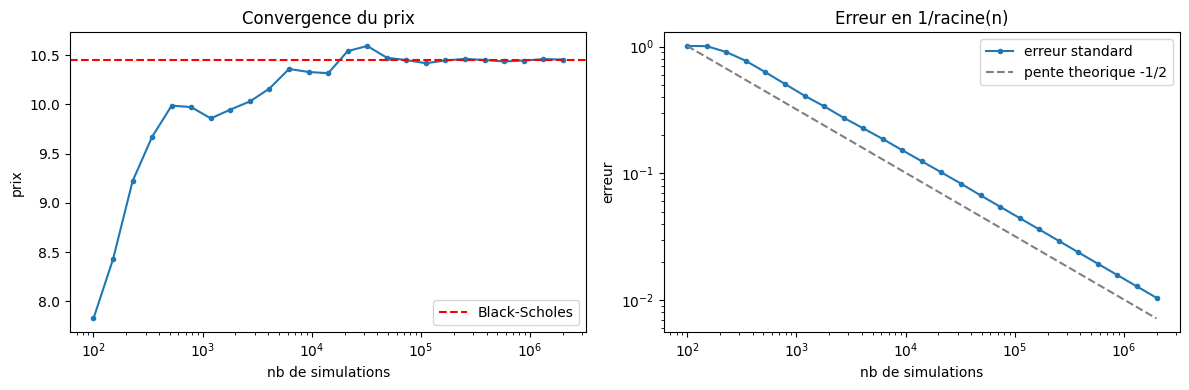

In [4]:
def prix_mc_europeen(S, K, r, sigma, T, n, type_option="call", antithetique=False, graine=0):
    rng = np.random.default_rng(graine)
    Z = rng.standard_normal(n)
    if antithetique:
        Z = np.concatenate([Z, -Z])  # chaque tirage et son oppose
    ST = S * np.exp((r - sigma**2/2)*T + sigma*np.sqrt(T)*Z)
    payoff = np.maximum(ST - K, 0) if type_option == "call" else np.maximum(K - ST, 0)
    actualise = np.exp(-r*T) * payoff
    prix = actualise.mean()
    erreur = actualise.std(ddof=1) / np.sqrt(len(actualise))  # erreur standard de Monte-Carlo
    return prix, erreur

prix_mc, erreur_mc = prix_mc_europeen(prix_initial, prix_exercice, taux, volatilite, maturite, NB_SIMULATIONS, TYPE_OPTION, graine=GRAINE)
print(f"Prix Monte-Carlo ({TYPE_OPTION}) : {prix_mc:.4f}  +/- {1.96*erreur_mc:.4f}  (IC 95%)")
print(f"Prix Black-Scholes      : {prix_vanille_bs:.4f}")

# Convergence : le prix se stabilise et l'erreur decroit en 1/racine(n)
tailles = np.logspace(2, 6.3, 25).astype(int)
prix_par_taille   = [prix_mc_europeen(prix_initial, prix_exercice, taux, volatilite, maturite, n, TYPE_OPTION, graine=GRAINE)[0] for n in tailles]
erreur_par_taille = [prix_mc_europeen(prix_initial, prix_exercice, taux, volatilite, maturite, n, TYPE_OPTION, graine=GRAINE)[1] for n in tailles]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(tailles, prix_par_taille, "o-", ms=3); a1.axhline(prix_vanille_bs, ls="--", color="red", label="Black-Scholes")
a1.set_xscale("log"); a1.set_xlabel("nb de simulations"); a1.set_ylabel("prix"); a1.legend(); a1.set_title("Convergence du prix")
a2.loglog(tailles, erreur_par_taille, "o-", ms=3, label="erreur standard")
a2.loglog(tailles, erreur_par_taille[0]*np.sqrt(tailles[0]/tailles), "--", color="grey", label="pente theorique -1/2")
a2.set_xlabel("nb de simulations"); a2.set_ylabel("erreur"); a2.legend(); a2.set_title("Erreur en 1/racine(n)")
plt.tight_layout(); plt.show()

Le Monte-Carlo donne 10.4634 pour le call, contre 10.4506 pour Black-Scholes : l'ecart (0.013) tient dans l'intervalle de confiance a 95% (+/- 0.065). La methode est donc validee, et l'erreur decroit en 1/racine(n), une vitesse independante de la dimension.

# Partie V : réduction de variance (antithétique, variable de contrôle)

Puisque l'erreur décroît seulement en $1/\sqrt{n}$, augmenter $n$ coûte cher. Une bien meilleure stratégie est de réduire la variance de l'estimateur à coût constant. J'illustre les deux techniques les plus classiques.

Les **variables antithétiques** consistent à utiliser, pour chaque tirage $Z$, aussi son opposé $-Z$. Comme le payoff est négativement corrélé entre les deux, leur moyenne a une variance plus faible, pour le même nombre de tirages aléatoires.

La **variable de contrôle** exploite une quantité corrélée au payoff dont je connais l'espérance exacte. Ici, j'utilise le sous-jacent actualisé $e^{-rT}S_T$, dont l'espérance risque-neutre vaut exactement $S_0$. En corrigeant l'estimateur par cette quantité (avec un coefficient $\beta$ optimal estimé par régression), j'élimine une grande partie du bruit. Je compare les trois erreurs standard.

In [5]:
def prix_mc_controle(S, K, r, sigma, T, n, type_option="call", graine=0):
    # Variable de controle : le sous-jacent actualise e^-rT * S_T, dont l'esperance vaut S0
    rng = np.random.default_rng(graine)
    Z = rng.standard_normal(n)
    ST = S * np.exp((r - sigma**2/2)*T + sigma*np.sqrt(T)*Z)
    brut = np.exp(-r*T) * (np.maximum(ST - K, 0) if type_option == "call" else np.maximum(K - ST, 0))
    controle = np.exp(-r*T) * ST
    beta = np.cov(brut, controle)[0, 1] / np.var(controle)
    ajuste = brut - beta * (controle - S)  # meme esperance, variance plus faible
    return ajuste.mean(), ajuste.std(ddof=1) / np.sqrt(n)

n = NB_SIMULATIONS
_, erreur_naif = prix_mc_europeen(prix_initial, prix_exercice, taux, volatilite, maturite, n, TYPE_OPTION, graine=GRAINE)
_, erreur_anti = prix_mc_europeen(prix_initial, prix_exercice, taux, volatilite, maturite, n, TYPE_OPTION, antithetique=True, graine=GRAINE)
_, erreur_ctrl = prix_mc_controle(prix_initial, prix_exercice, taux, volatilite, maturite, n, TYPE_OPTION, graine=GRAINE)
print(f"Erreur standard (demi-IC 95%) pour n = {n:,} :")
print(f"  Monte-Carlo naif        : +/- {1.96*erreur_naif:.4f}")
print(f"  Variables antithetiques : +/- {1.96*erreur_anti:.4f}   (reduction x{erreur_naif/erreur_anti:.1f})")
print(f"  Variable de controle    : +/- {1.96*erreur_ctrl:.4f}   (reduction x{erreur_naif/erreur_ctrl:.1f})")

Erreur standard (demi-IC 95%) pour n = 200,000 :
  Monte-Carlo naif        : +/- 0.0649
  Variables antithetiques : +/- 0.0458   (reduction x1.4)
  Variable de controle    : +/- 0.0247   (reduction x2.6)


Les techniques de reduction de variance resserrent l'intervalle de confiance a budget de simulation egal : les variables antithetiques font passer le demi-IC de 0.065 a 0.046, la variable de controle fait encore mieux. On atteint donc la meme precision avec bien moins de trajectoires.

# Partie VI : les Greeks par Monte-Carlo

Les Greeks (sensibilités du prix aux paramètres) sont aussi importants que le prix lui-même pour couvrir une position. Je prends le call comme exemple canonique et j'en calcule le Delta de trois façons, que je confronte aux formules analytiques de Black-Scholes ; le cas du put s'en déduit par parité (son Delta vaut celui du call moins un).

La méthode des **différences finies** rejoue le pricing en décalant légèrement $S_0$ : $\Delta \approx (\text{prix}(S_0+h) - \text{prix}(S_0-h))/2h$. Le piège classique est d'utiliser des tirages aléatoires différents pour les deux prix, ce qui noierait le Delta dans le bruit. J'emploie donc les **mêmes nombres aléatoires** (common random numbers) pour les deux évaluations, ce qui réduit massivement la variance de la différence.

La méthode **pathwise** dérive directement le payoff le long de la trajectoire ; elle est précise mais suppose un payoff continu. La méthode **likelihood ratio** dérive au contraire la densité de probabilité et fonctionne même pour des payoffs discontinus. C'est un joli parallèle avec le projet APR, où j'obtenais les Greeks par différentiation automatique : ici, je les obtiens par simulation.

In [6]:
# Greeks analytiques de Black-Scholes (reference, sur le call)
d1 = (np.log(prix_initial/prix_exercice) + (taux + volatilite**2/2)*maturite) / (volatilite*np.sqrt(maturite))
delta_bs = norm.cdf(d1)
gamma_bs = norm.pdf(d1) / (prix_initial * volatilite * np.sqrt(maturite))

# Methode 1 : differences finies avec nombres aleatoires communs (indispensable pour reduire le bruit)
rng = np.random.default_rng(GRAINE)
Z = rng.standard_normal(500_000)
def prix_call_commun(S):
    ST = S * np.exp((taux - volatilite**2/2)*maturite + volatilite*np.sqrt(maturite)*Z)
    return np.exp(-taux*maturite) * np.maximum(ST - prix_exercice, 0).mean()
h = 0.5
delta_df = (prix_call_commun(prix_initial + h) - prix_call_commun(prix_initial - h)) / (2*h)
gamma_df = (prix_call_commun(prix_initial + h) - 2*prix_call_commun(prix_initial) + prix_call_commun(prix_initial - h)) / h**2

# Methode 2 : derivee pathwise (je derive le payoff le long de la trajectoire)
ST = prix_initial * np.exp((taux - volatilite**2/2)*maturite + volatilite*np.sqrt(maturite)*Z)
delta_pathwise = np.exp(-taux*maturite) * np.mean((ST > prix_exercice) * ST / prix_initial)

# Methode 3 : likelihood ratio (je derive la densite, valable meme pour un payoff discontinu)
delta_lr = np.exp(-taux*maturite) * np.mean(np.maximum(ST - prix_exercice, 0) * Z / (prix_initial*volatilite*np.sqrt(maturite)))

print(f"Delta (call)  ->  Black-Scholes : {delta_bs:.4f} | diff. finies : {delta_df:.4f} | pathwise : {delta_pathwise:.4f} | likelihood ratio : {delta_lr:.4f}")
print(f"Gamma (call)  ->  Black-Scholes : {gamma_bs:.4f} | diff. finies : {gamma_df:.4f}")

Delta (call)  ->  Black-Scholes : 0.6368 | diff. finies : 0.6361 | pathwise : 0.6361 | likelihood ratio : 0.6382
Gamma (call)  ->  Black-Scholes : 0.0188 | diff. finies : 0.0188


Les trois methodes de calcul du Delta (differences finies, pathwise, likelihood ratio) convergent vers la valeur analytique de Black-Scholes (0.637). Chacune a son domaine : la pathwise pour les payoffs continus, le likelihood ratio pour les payoffs discontinus, les differences finies comme solution generale mais plus bruitee.

# Partie VII : options path-dependent (asiatique, barrière)

C'est ici que le Monte-Carlo devient indispensable plutôt que simplement pratique : pour ces options, le payoff dépend de toute la trajectoire et aucune formule fermée simple n'existe. Je réutilise donc la simulation pas à pas de la Partie III, et j'écris des fonctions génériques (call ou put) que la fonction `pricer` réutilisera ensuite.

L'**option asiatique** a un payoff basé sur la moyenne du prix sur la période, et non sur le seul prix final. Cette moyenne lisse la volatilité, donc l'option asiatique est moins chère que la vanille. C'est un produit très courant sur les marchés de matières premières et de change.

L'**option à barrière désactivante** (up-and-out) s'annule si le sous-jacent franchit le niveau de barrière à un moment quelconque. Elle est donc moins chère qu'une vanille, puisqu'une partie des scénarios voit l'option disparaître. Ces deux exemples montrent pourquoi la simulation de trajectoires est le bon outil.

In [7]:
def prix_asiatique(S, K, r, sigma, T, n, nb_pas, type_option="call", graine=0):
    chemins = simuler_trajectoires(S, r, sigma, T, n, nb_pas, graine)
    moyenne = chemins[:, 1:].mean(axis=1)  # moyenne arithmetique du prix
    payoff = np.maximum(moyenne - K, 0) if type_option == "call" else np.maximum(K - moyenne, 0)
    return np.exp(-r*T) * payoff.mean()

def prix_barriere(S, K, r, sigma, T, n, nb_pas, barriere, type_option="call", graine=0):
    chemins = simuler_trajectoires(S, r, sigma, T, n, nb_pas, graine)
    reste_active = chemins.max(axis=1) < barriere  # up-and-out : annulee si le prix touche B
    ST = chemins[:, -1]
    payoff = np.maximum(ST - K, 0) if type_option == "call" else np.maximum(K - ST, 0)
    return np.exp(-r*T) * np.mean(reste_active * payoff)

prix_asia = prix_asiatique(prix_initial, prix_exercice, taux, volatilite, maturite, NB_SIMULATIONS, NB_PAS, TYPE_OPTION, GRAINE)
prix_bar  = prix_barriere(prix_initial, prix_exercice, taux, volatilite, maturite, NB_SIMULATIONS, NB_PAS, BARRIERE, TYPE_OPTION, GRAINE)
print(f"{TYPE_OPTION} vanille (Black-Scholes)        : {prix_vanille_bs:.4f}")
print(f"{TYPE_OPTION} asiatique (moyenne)            : {prix_asia:.4f}   (moins cher : la moyenne lisse la volatilite)")
print(f"{TYPE_OPTION} up-and-out (barriere B={BARRIERE:.0f})    : {prix_bar:.4f}   (moins cher : une partie des trajectoires est annulee)")

call vanille (Black-Scholes)        : 10.4506
call asiatique (moyenne)            : 5.8048   (moins cher : la moyenne lisse la volatilite)
call up-and-out (barriere B=130)    : 3.5826   (moins cher : une partie des trajectoires est annulee)


L'option asiatique (5.80) est nettement moins chere que la vanille (10.45) : moyenner le sous-jacent lisse la volatilite, donc reduit la valeur temps. L'option a barriere est encore moins chere, car elle ne paie que sur les trajectoires qui ne touchent pas la barriere. Ces payoffs n'ont pas de formule fermee simple, d'ou l'interet du Monte-Carlo.

# Partie VIII : options américaines (Longstaff-Schwartz)

Les options américaines peuvent être exercées à tout moment, ce qui pose un problème particulier au Monte-Carlo : à chaque date, il faut décider d'exercer ou de continuer, en comparant le gain immédiat à la **valeur de continuation** (l'espérance du gain futur si l'on n'exerce pas). Cette valeur de continuation n'est pas observable directement.

L'algorithme de **Longstaff-Schwartz** (2001) résout ce problème de façon élégante et est devenu la méthode standard. Je simule les trajectoires, puis je remonte le temps depuis la maturité : à chaque date, pour les trajectoires dans la monnaie, j'estime la valeur de continuation par une **régression** des gains futurs actualisés sur des fonctions de base du prix (ici un polynôme de degré 2). J'exerce lorsque le gain immédiat dépasse cette valeur de continuation estimée. J'utilise un nombre modéré de dates d'exercice (approximation bermudienne, suffisante et standard).

Je l'illustre sur un put. Comme un call américain sur une action sans dividende ne s'exerce jamais par anticipation (il vaut son équivalent européen), c'est le put qui révèle la **prime d'exercice anticipé** : le put américain vaut strictement plus que le put européen.

In [8]:
def prix_americain_lsm(S, K, r, sigma, T, n, nb_dates, type_option="put", graine=0):
    chemins = simuler_trajectoires(S, r, sigma, T, n, nb_dates, graine)
    dt = T / nb_dates
    def gain(prix):
        return np.maximum(K - prix, 0) if type_option == "put" else np.maximum(prix - K, 0)
    valeur = gain(chemins[:, -1])  # valeur si on exerce a maturite
    t_exercice = np.full(n, nb_dates)
    for t in range(nb_dates - 1, 0, -1):
        St = chemins[:, t]
        valeur_immediate = gain(St)
        dans_la_monnaie = valeur_immediate > 0
        if dans_la_monnaie.sum() > 0:
            X = St[dans_la_monnaie]
            # valeur de continuation = esperance du gain futur, estimee par regression
            Y = valeur[dans_la_monnaie] * np.exp(-r * (t_exercice[dans_la_monnaie] - t) * dt)
            base = np.vstack([np.ones_like(X), X, X**2]).T
            coefficients = np.linalg.lstsq(base, Y, rcond=None)[0]
            continuation = base @ coefficients
            on_exerce = valeur_immediate[dans_la_monnaie] > continuation
            indices = np.where(dans_la_monnaie)[0][on_exerce]
            valeur[indices] = valeur_immediate[dans_la_monnaie][on_exerce]
            t_exercice[indices] = t
    return np.mean(valeur * np.exp(-r * t_exercice * dt))

NB_DATES_EXERCICE = 50
put_us = prix_americain_lsm(prix_initial, prix_exercice, taux, volatilite, maturite, 100_000, NB_DATES_EXERCICE, "put", GRAINE)
print(f"Put europeen (Black-Scholes)        : {put_bs:.4f}")
print(f"Put americain (Longstaff-Schwartz)  : {put_us:.4f}")
print(f"Prime d'exercice anticipe           : {put_us - put_bs:.4f}")

Put europeen (Black-Scholes)        : 5.5735
Put americain (Longstaff-Schwartz)  : 6.0247
Prime d'exercice anticipe           : 0.4512


Le put americain (6.02) vaut plus que le put europeen (5.57) : la difference (0.45) est la prime d'exercice anticipe, la valeur du droit d'exercer avant l'echeance. Longstaff-Schwartz l'estime en regressant la valeur de continuation sur des fonctions de base, et fournit une borne basse du vrai prix.

# Partie IX : un pricer unifié et réutilisable

Je rassemble enfin toutes les méthodes derrière une seule fonction, `pricer`, qui lit la configuration du haut du notebook et valorise la famille de produit demandée. C'est l'aboutissement de la démarche : pour un nouveau cas, je modifie le bloc de configuration de la Partie I, puis j'appelle `pricer`. La fonction est le **point d'entrée unique** de l'outil ; ses paramètres optionnels permettent de surcharger ponctuellement la configuration (par exemple pricer un put alors que la config est en call) sans rien réécrire.

J'illustre en valorisant d'un coup, sur le sous-jacent configuré, les quatre familles de produits. On retrouve bien que le call américain vaut son équivalent européen (pas d'exercice anticipé sans dividende), alors que pour un put l'écart serait positif.

In [9]:
def pricer(famille="europeen", type_option=None, n=None, graine=None):
    """Point d'entree unique du pricer.
    famille : 'europeen' | 'asiatique' | 'barriere' | 'americain'.
    Les parametres non precises sont lus dans la configuration globale (Partie I)."""
    type_option = TYPE_OPTION if type_option is None else type_option
    n = NB_SIMULATIONS if n is None else n
    graine = GRAINE if graine is None else graine
    if famille == "europeen":
        return prix_mc_europeen(prix_initial, prix_exercice, taux, volatilite, maturite,
                                n, type_option, antithetique=True, graine=graine)[0]
    if famille == "asiatique":
        return prix_asiatique(prix_initial, prix_exercice, taux, volatilite, maturite,
                              n, NB_PAS, type_option, graine)
    if famille == "barriere":
        return prix_barriere(prix_initial, prix_exercice, taux, volatilite, maturite,
                             n, NB_PAS, BARRIERE, type_option, graine)
    if famille == "americain":
        return prix_americain_lsm(prix_initial, prix_exercice, taux, volatilite, maturite,
                                  min(n, 100_000), NB_DATES_EXERCICE, type_option, graine)
    raise ValueError(f"famille inconnue : {famille}")

print(f"Produit configure : {TYPE_OPTION} sur {NOM_SOUS_JACENT}, K = {prix_exercice}, T = {maturite} an")
print()
for famille in ["europeen", "asiatique", "barriere", "americain"]:
    print(f"  {famille:10s} : {pricer(famille):8.4f}")

# Exemple de surcharge ponctuelle : le meme moteur, sur un put, sans toucher a la configuration
print()
print(f"Surcharge -> put europeen : {pricer('europeen', type_option='put'):.4f}  (Black-Scholes : {put_bs:.4f})")

Produit configure : call sur Action ABC, K = 100.0, T = 1.0 an

  europeen   :  10.4720


  asiatique  :   5.8048


  barriere   :   3.5826


  americain  :  10.5216

Surcharge -> put europeen : 5.5838  (Black-Scholes : 5.5735)


La fonction pricer unique price les quatre familles (europeen, asiatique, barriere, americain) depuis le meme bloc de configuration. On retrouve la hierarchie attendue : la barriere la moins chere, puis l'asiatique, puis l'europeen, et l'americain au-dessus du fait de la prime d'exercice.

# Partie X : validation sur tout le spectre de moneyness (ITM, ATM, OTM)

Mon pricer ne repose sur aucune hypothèse de moneyness : le strike $K$ n'est qu'un paramètre. Pour le vérifier, je price le call et le put européens sur toute une grille de strikes, du cas très en dehors de la monnaie au cas très dans la monnaie, et je superpose le prix Monte-Carlo au prix Black-Scholes. Les deux doivent coïncider partout, ce qui prouve que l'outil valorise n'importe quelle option. Pour rappel, côté call, $K > S_0$ correspond à une option OTM et $K < S_0$ à une option ITM ; c'est l'inverse pour un put ; $K = S_0$ est le cas ATM. La fonction `pricer` hérite directement de cette généralité, puisqu'elle s'appuie sur les mêmes fonctions.

Call europeen :   etat  strike |   MC     |   BS     |  ecart
                  ITM     80 |  24.6081 |  24.5888 | +0.0192
                  ATM    100 |  10.4720 |  10.4506 | +0.0214
                  OTM    120 |   3.2696 |   3.2475 | +0.0221

Ecart absolu maximal (call) sur toute la grille : 0.0229
Ecart absolu maximal (put)  sur toute la grille : 0.0118


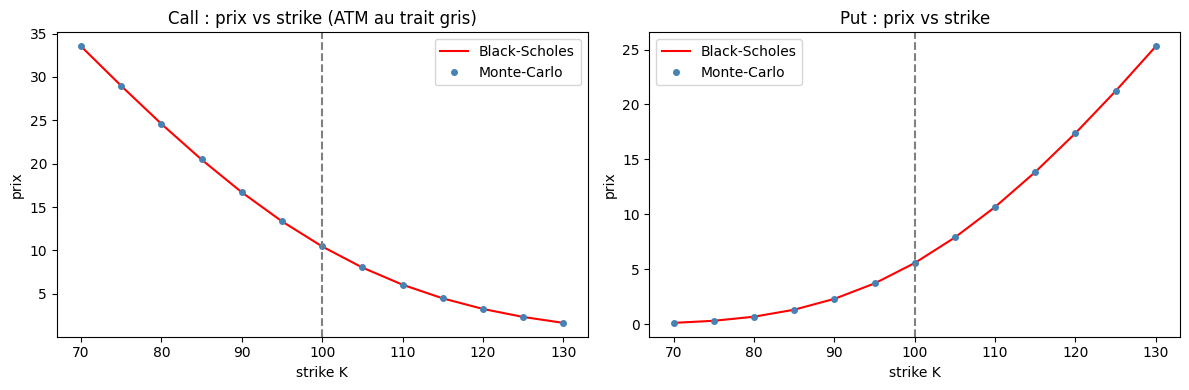

In [10]:
# Je price call et put europeens sur une grille de strikes (deep ITM -> deep OTM cote call)
strikes = np.arange(70, 131, 5)
lignes = []
for K in strikes:
    call_mc = prix_mc_europeen(prix_initial, K, taux, volatilite, maturite, NB_SIMULATIONS, "call", antithetique=True, graine=GRAINE)[0]
    put_mc  = prix_mc_europeen(prix_initial, K, taux, volatilite, maturite, NB_SIMULATIONS, "put",  antithetique=True, graine=GRAINE)[0]
    lignes.append((K, call_mc, prix_black_scholes(prix_initial, K, taux, volatilite, maturite, "call"),
                      put_mc,  prix_black_scholes(prix_initial, K, taux, volatilite, maturite, "put")))
strikes_arr = np.array([l[0] for l in lignes])
call_mc_arr = np.array([l[1] for l in lignes]); call_bs_arr = np.array([l[2] for l in lignes])
put_mc_arr  = np.array([l[3] for l in lignes]); put_bs_arr  = np.array([l[4] for l in lignes])

# Table a trois strikes representatifs (OTM / ATM / ITM pour le call)
print("Call europeen :   etat  strike |   MC     |   BS     |  ecart")
for K, cmc, cbs, pmc, pbs in lignes:
    if K in (80, 100, 120):
        etat = "ITM" if K < prix_initial else ("ATM" if K == prix_initial else "OTM")
        print(f"                  {etat}  {K:5.0f} | {cmc:8.4f} | {cbs:8.4f} | {cmc-cbs:+.4f}")
print()
print(f"Ecart absolu maximal (call) sur toute la grille : {np.abs(call_mc_arr-call_bs_arr).max():.4f}")
print(f"Ecart absolu maximal (put)  sur toute la grille : {np.abs(put_mc_arr-put_bs_arr).max():.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(strikes_arr, call_bs_arr, "-", color="red", label="Black-Scholes")
a1.plot(strikes_arr, call_mc_arr, "o", ms=4, color="steelblue", label="Monte-Carlo")
a1.axvline(prix_initial, ls="--", color="grey"); a1.set_title("Call : prix vs strike (ATM au trait gris)")
a1.set_xlabel("strike K"); a1.set_ylabel("prix"); a1.legend()
a2.plot(strikes_arr, put_bs_arr, "-", color="red", label="Black-Scholes")
a2.plot(strikes_arr, put_mc_arr, "o", ms=4, color="steelblue", label="Monte-Carlo")
a2.axvline(prix_initial, ls="--", color="grey"); a2.set_title("Put : prix vs strike")
a2.set_xlabel("strike K"); a2.set_ylabel("prix"); a2.legend()
plt.tight_layout(); plt.show()

La validation finale confronte Monte-Carlo et Black-Scholes sur toute la gamme de moneyness (ITM, ATM, OTM), pour les calls et les puts. Les ecarts restent partout dans le bruit statistique (quelques centiemes), ce qui confirme que le pricer est correct sur l'ensemble du spectre, pas seulement a la monnaie.

# Partie XI : bilan et limites

## Bilan
J'ai construit un pricer Monte-Carlo complet, configurable et réutilisable, validé à chaque étape contre Black-Scholes. Le notebook couvre toute la chaîne classique : simulation risque-neutre du sous-jacent, pricing européen avec intervalle de confiance et convergence en $1/\sqrt{n}$, réduction de variance, calcul des Greeks par trois méthodes, options path-dependent (asiatique, barrière), options américaines par Longstaff-Schwartz, et une fonction `pricer` unique pilotée par un bloc de configuration. Avec la formule de Black-Scholes (analytique) et le réseau de neurones du projet APR (apprentissage), j'ai désormais les trois grands paradigmes de valorisation d'options.

## Limites et extensions
Mon modèle suppose une volatilité et un taux constants : l'extension naturelle est un modèle à volatilité locale (Dupire) ou stochastique (Heston), qui reproduit le smile de volatilité. La simulation est ici exacte pour le mouvement brownien géométrique, mais pour des modèles plus riches il faudrait gérer le biais de discrétisation (schéma d'Euler contre schémas d'ordre supérieur). Je reste sur un seul sous-jacent, alors que le Monte-Carlo prend tout son intérêt sur des paniers multi-actifs (simulation corrélée par Cholesky, exactement comme dans mon projet Risk Engine). Enfin, la réduction de variance pourrait aller plus loin (échantillonnage préférentiel, quasi-Monte-Carlo avec suites de Sobol).
